# Olist: retention, CLV and delivery experience
Walk-through of the analysis behind the README. Queries run live against the DuckDB warehouse built by `src/run_pipeline.py`.

In [1]:
import os, sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import analysis, config, data
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
results = json.loads(config.RESULTS_JSON.read_text())

## 1. Data quality and row counts

In [2]:
display(pd.read_csv('reports/tables/quality_checks.csv'))
data.row_counts()

,rule,severity,failures
0,orders: order_id is unique,hard,0
1,customers: customer_id is unique,hard,0
2,"items: (order_id, order_item_id) is unique",hard,0
3,orders: every order has a customer,hard,0
4,items: every item belongs to a known order,hard,0
5,items: every item has a known product and seller,hard,0
6,items: price > 0 and freight >= 0,hard,0
7,reviews: score between 1 and 5,hard,0
8,orders: delivered status without delivery date,soft,8
9,orders: delivered before purchase,soft,0


{'raw_orders': 99441,
 'raw_customers': 99441,
 'raw_items': 112650,
 'raw_payments': 103886,
 'raw_reviews': 99224,
 'raw_products': 32951,
 'raw_sellers': 3095,
 'raw_geolocation': 1000163,
 'fact_orders': 98198,
 'fact_order_items': 112100,
 'dim_customer': 94983}

## 2. The business at a glance (SQL window functions)

In [3]:
data.query('08_monthly_kpis.sql').tail(12)

,purchase_month,orders,customers,gmv,avg_order_value,late_rate,avg_review,gmv_mom_growth,gmv_rolling_3m
11,2017-09-01,4227,4154,"717,195.2200",169.6700,0.0439,4.2217,0.0833,"1,958,125.5700"
12,2017-10-01,4547,4481,"764,785.2800",168.1956,0.0418,4.1736,0.0664,"2,144,052.2700"
13,2017-11-01,7421,7313,"1,172,355.5400",157.9781,0.1240,3.9493,0.5329,"2,654,336.0400"
14,2017-12-01,5618,5551,"861,647.6500",153.3727,0.0746,4.0405,-0.2650,"2,798,788.4700"
15,2018-01-01,7187,7088,"1,102,639.4100",153.4214,0.0570,4.0675,0.2797,"3,136,642.6000"
16,2018-02-01,6624,6468,"979,828.6300",147.9210,0.1413,3.8591,-0.1114,"2,944,115.6900"
17,2018-03-01,7168,7077,"1,152,736.7400",160.8171,0.1896,3.7636,0.1765,"3,235,204.7800"
18,2018-04-01,6919,6863,"1,156,303.9100",167.1201,0.0450,4.1699,0.0031,"3,288,869.2800"
19,2018-05-01,6833,6775,"1,145,748.6300",167.6787,0.0656,4.2105,-0.0091,"3,454,789.2800"
20,2018-06-01,6145,6106,"1,020,494.2900",166.0690,0.0116,4.2878,-0.1093,"3,322,546.8300"


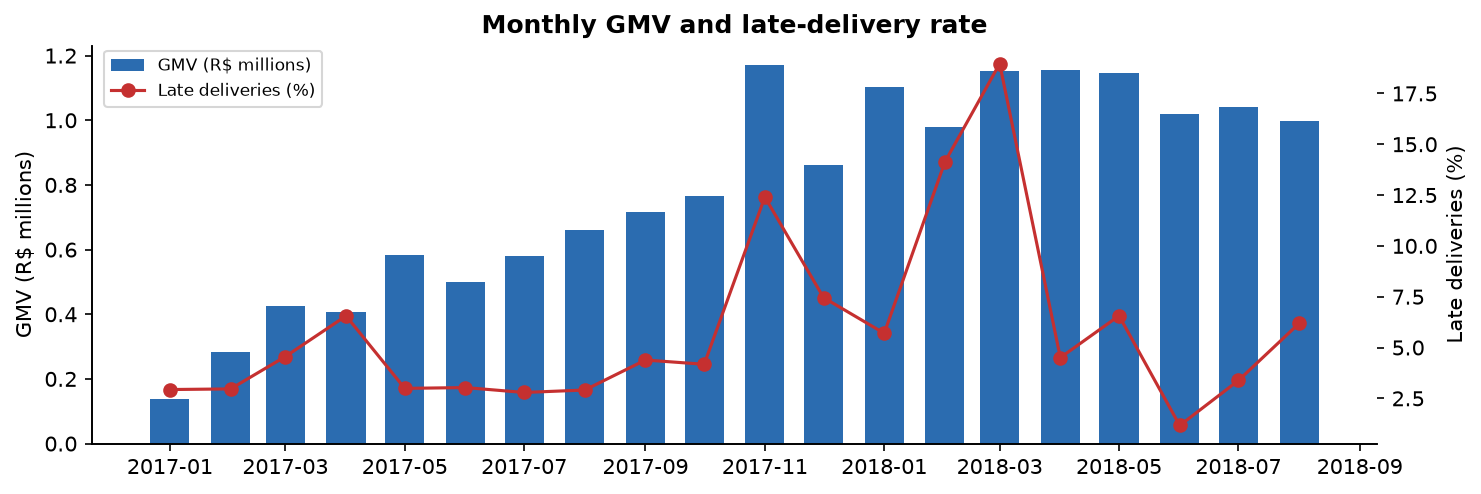

In [4]:
display(Image(filename='reports/figures/01_monthly_gmv_late_rate.png'))

## 3. Retention: monthly cohorts

In [5]:
coh = data.query('05_cohort_retention.sql')
coh.pivot_table(index='cohort_month', columns='months_since_first', values='retention_rate').iloc[:, :7]

months_since_first,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01-01,1.0000,0.0040,0.0027,0.0013,0.0040,0.0013,0.0040
2017-02-01,1.0000,0.0024,0.0030,0.0012,0.0041,0.0012,0.0024
2017-03-01,1.0000,0.0051,0.0035,0.0039,0.0035,0.0016,0.0016
2017-04-01,1.0000,0.0060,0.0022,0.0017,0.0030,0.0026,0.0034
2017-05-01,1.0000,0.0048,0.0048,0.0040,0.0031,0.0034,0.0042
2017-06-01,1.0000,0.0045,0.0035,0.0039,0.0026,0.0039,0.0035
2017-07-01,1.0000,0.0052,0.0034,0.0024,0.0029,0.0021,0.0031
2017-08-01,1.0000,0.0068,0.0034,0.0027,0.0036,0.0053,0.0029
2017-09-01,1.0000,0.0069,0.0054,0.0029,0.0044,0.0022,0.0022


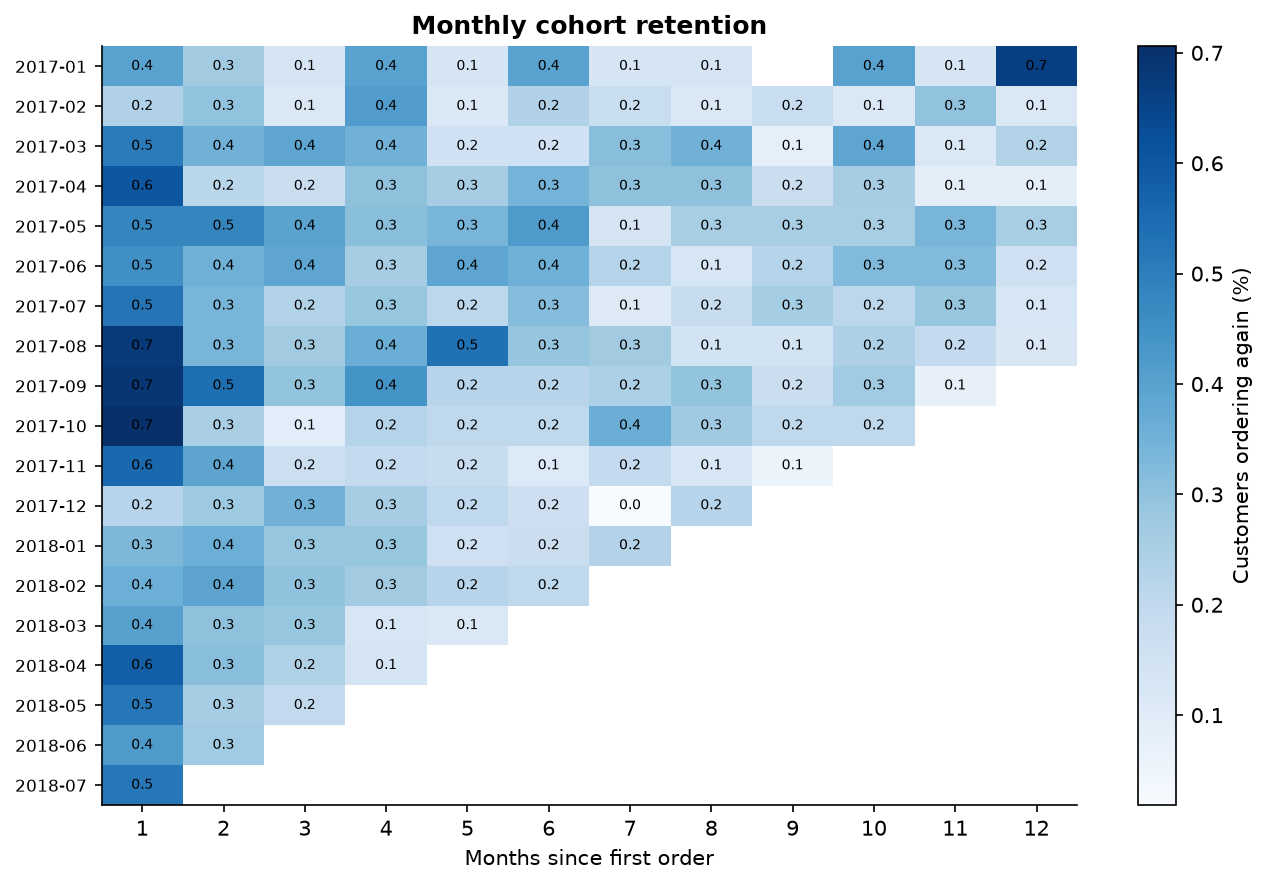

In [6]:
display(Image(filename='reports/figures/02_cohort_retention.png'))

## 4. Delivery and reviews

In [7]:
orders = data.table('fact_orders')
d = analysis.delivered_reviewed(orders)
analysis.review_by_lateness(d)

{'late_orders': 6381,
 'ontime_orders': 89443,
 'late_share': 0.06659083319418935,
 'mean_review_late': 2.270490518727472,
 'mean_review_ontime': 4.290386055923885,
 'negative_rate_late': 0.6241968343519825,
 'negative_rate_ontime': 0.09267354628087161,
 'mean_diff': -2.0198955371964127,
 'mean_diff_ci': [-2.0575090240574596, -1.9818648117337339],
 'mann_whitney_u': 103305546.0,
 'p_value': 0.0,
 'rank_biserial': 0.6379916974646743}

In [8]:
analysis.review_by_delay_bucket(d)

,delay_bucket,orders,avg_review,negative_rate
0,On time,89443,4.2904,0.0927
1,1-3 days late,1852,3.2910,0.3213
2,4-7 days late,1748,2.1030,0.6768
3,8-14 days late,1446,1.6708,0.8015
4,15+ days late,1335,1.7236,0.7835


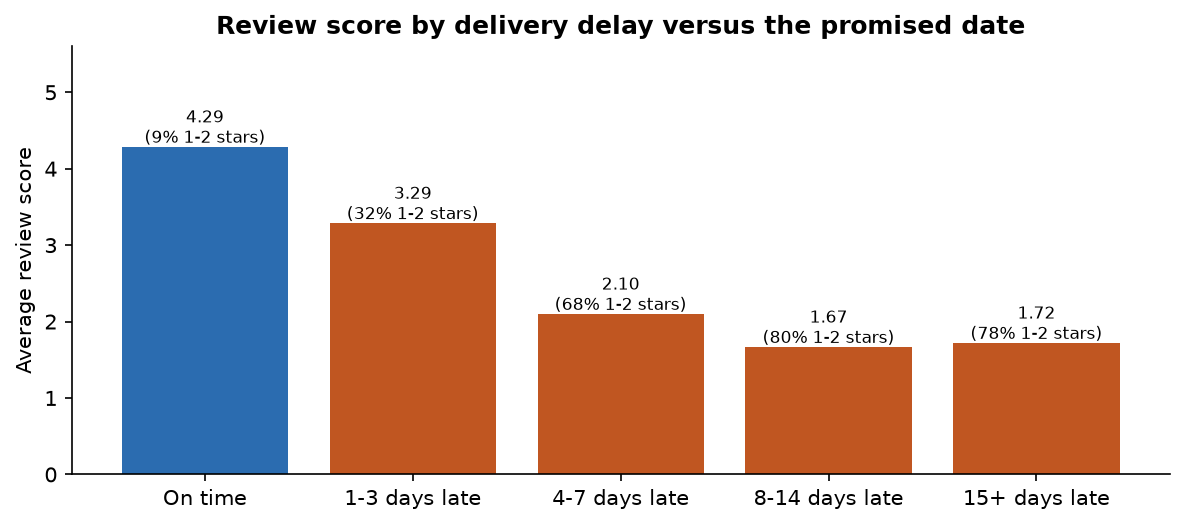

{'n': 95824,
 'coef_is_late': -2.6836771148413336,
 'se_is_late': 0.02650774141967802,
 'odds_ratio_higher_score': 0.0683115025220964,
 'or_ci': [0.06485298836954825, 0.07195445412994295],
 'p_value': 0.0,
 'p_negative_if_late': 0.5993888515830704,
 'p_negative_if_ontime': 0.09765393670440731,
 'controls': ['log_distance_km',
  'log_order_value',
  'freight_ratio',
  'multi_item',
  'multi_seller',
  'cat_auto',
  'cat_bed_bath_table',
  'cat_computers_accessories',
  'cat_cool_stuff',
  'cat_furniture_decor',
  'cat_garden_tools',
  'cat_health_beauty',
  'cat_housewares',
  'cat_sports_leisure',
  'cat_telephony',
  'cat_toys',
  'cat_watches_gifts']}

In [9]:
display(Image(filename='reports/figures/03_review_by_delay.png'))
results['ordinal_model']

In [10]:
data.query('06_delivery_kpis.sql').head(10)

,customer_state,delivered_orders,late_rate,avg_delivery_days,avg_promised_days,avg_review,avg_distance_km,avg_freight_ratio
0,SP,40494,0.0449,8.7006,19.7761,4.2458,249.6017,0.2520
1,RJ,12350,0.1211,15.2370,26.9982,3.9654,488.5495,0.3159
2,MG,11354,0.0457,11.9450,25.1880,4.1923,532.6719,0.3161
3,RS,5344,0.0608,15.2485,29.1589,4.1848,863.6853,0.3395
4,PR,4923,0.0404,11.9380,25.2523,4.2398,485.7049,0.3349
5,SC,3546,0.0821,14.9030,26.4064,4.1336,572.4794,0.3302
6,BA,3256,0.1216,19.2786,30.0731,3.9306,"1,344.1538",0.3855
7,DF,2080,0.0567,12.8990,24.9471,4.1314,836.7839,0.3355
8,ES,1995,0.1073,15.7238,26.2201,4.0787,802.2415,0.3466
9,GO,1957,0.0654,15.5360,27.7215,4.1059,778.2382,0.3437


## 5. Does a late first order reduce repeat purchases?

In [11]:
results['repeat_vs_first_delivery']

{'customers': 56199,
 'repeat_rate_overall': 0.031690955355077495,
 'repeat_rate_late': 0.027906976744186046,
 'repeat_rate_ontime': 0.03197080012994707,
 'diff': -0.0040638233857610215,
 'diff_ci': [-0.009467628963195487, 0.0013399821916734453],
 'z_p_value': 0.1637444885657653,
 'logit_odds_ratio': 0.8803197635808535,
 'logit_or_ci': [0.7182791712540041, 1.078915994178259],
 'logit_p_value': 0.21938588154875072}

## 6. Segments and CLV

In [12]:
display(pd.read_csv('reports/tables/rfm_segments.csv'))
display(pd.read_csv('reports/tables/kmeans_k_selection.csv'))

,segment,customers,gmv,avg_recency_days,avg_orders,gmv_share
0,At-risk high-value,13985,"4,324,142.8700",396.9548,1.0000,0.2748
1,Champions (recent repeat),1240,"398,432.6900",90.9524,2.1556,0.0253
2,Hibernating low-value,22972,"1,672,404.9500",398.1636,1.0000,0.1063
3,Loyal repeaters,1646,"491,619.3500",323.3961,2.0826,0.0312
4,Needs attention,18387,"2,796,717.5000",222.2446,1.0000,0.1777
5,New high-value,14647,"4,439,272.4600",93.6860,1.0000,0.2821
6,New low-value,22106,"1,615,609.1300",91.6459,1.0000,0.1027


,k,silhouette,inertia
0,3,0.4092,"131,261.3856"
1,4,0.3953,"84,356.7448"
2,5,0.3538,"69,556.3590"
3,6,0.3527,"59,463.7693"


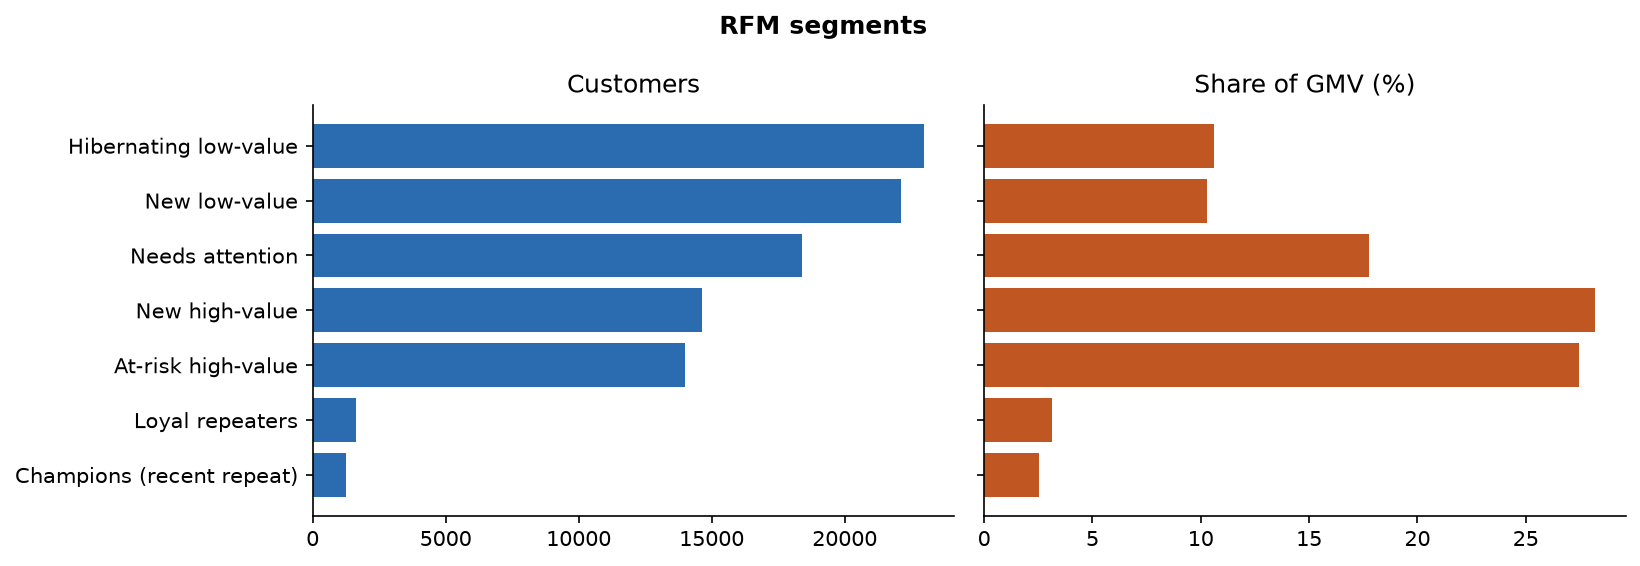

{'calibration_customers': 56319,
 'holdout_weeks': 26,
 'actual_purchases': 712.0,
 'predicted_purchases': 735.6733213222803,
 'error_pct': 0.03324904680095564,
 'params': {'r': 0.01648867035868438,
  'alpha': 9.35675001787597,
  'a': 1.3248681938101672,
  'b': 0.22080072552666072,
  'loglik': -8686.209671444174}}

In [13]:
display(Image(filename='reports/figures/05_rfm_segments.png'))
results['clv']['holdout']

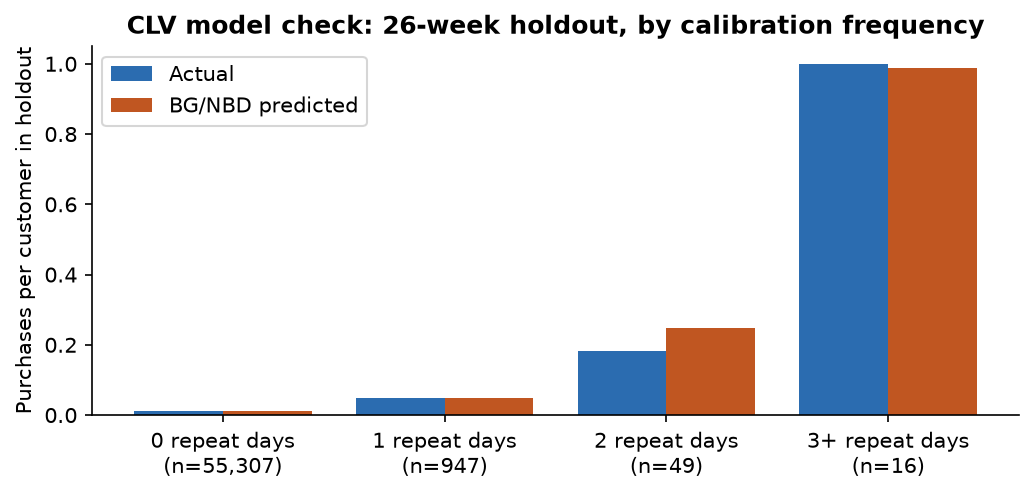

,customer_unique_id,x,t_x,T,monetary,exp_purchases_52w,prob_alive,exp_value_per_purchase,clv_12m_gmv
0,8d50f5eadf50201ccdcedfb9e2ac8455,15,66.0000,67.5714,56.3775,5.2217,0.8394,59.8599,312.5710
1,4facc2e6fbc2bffab2fea92d2b4aa7e4,3,60.1429,62.7143,440.1875,0.7230,0.5110,402.4432,290.9747
2,fe81bb32c243a86b2f86fbf053fe6140,4,34.5714,44.7143,318.1520,0.9238,0.4202,300.2840,277.3944
3,dc813062e0fc23409cd255f7f53c7074,5,59.7143,60.8571,182.4383,1.5371,0.6653,179.6763,276.1891
4,c8460e4251689ba205045f3ea17884a1,1,0.1429,3.4286,"2,327.9550",0.1499,0.1144,"1,823.7095",273.3519
5,397b44d5bb99eabf54ea9c2b41ebb905,3,22.4286,33.1429,439.1325,0.6357,0.3282,401.5264,255.2538
6,394ac4de8f3acb14253c177f0e15bc58,4,33.7143,36.0000,149.0820,1.3923,0.5748,149.4187,208.0364
7,ca77025e7201e3b30c44b472ff346268,6,33.5714,46.5714,160.3886,1.1060,0.3528,159.7395,176.6658
8,6469f99c1f9dfae7733b25662e7f1782,5,40.2857,49.4286,126.4717,1.2380,0.4813,128.8233,159.4875
9,d132b863416f85f2abb1a988ca05dd12,2,48.7143,54.5714,425.5067,0.3756,0.3557,379.7457,142.6202


In [14]:
display(Image(filename='reports/figures/06_clv_holdout.png'))
pd.read_csv('reports/tables/top_1000_customers_by_clv.csv').head(10)

## 7. Memo

In [15]:
display(Markdown(open('reports/memo.md').read()))

# Memo: why Olist customers do not return

**To:** Head of Customer Experience · **Data:** 98,198 Olist orders, 2016-09 to 2018-08

**What we found**

- **Retention is the gap.** 97.0% of 94,983 customers ordered only once; on average 0.48% of a monthly cohort orders again the next month.
- **Late deliveries drive bad reviews.** Late orders average 2.27 stars against 4.29 on time (difference -2.02, 95% CI -2.06 to -1.98; Mann-Whitney p < 0.001). Holding distance, order value, freight share, basket size and category fixed, an ordered logit puts the chance of a 1-2 star review at 59.9% for late orders versus 9.8% on time.
- **Lateness is concentrated.** 6.8% of deliveries are late overall; the worst large states are CE (13.8%, 1,279 orders), BA (12.2%, 3,256 orders), RJ (12.1%, 12,350 orders).
- **No clear retention penalty yet.** Customers whose first order arrived late re-ordered within 180 days at 2.79% versus 3.20% (difference -0.41 pts, 95% CI -0.95 to +0.13; logistic regression odds ratio 0.88, p = 0.22). The direction is negative but the interval includes zero.
- **The CLV model is well calibrated.** Fitted on orders to 2018-02-28, BG/NBD predicted 736 repeat purchase days in the next 26 weeks against 712 actual (+3.3%). Refitted on all data, it expects 1,559 repeat purchases worth R$237,233 in the next 12 months, 2.0% of last year's GMV.
- **Where the value sits.** 'New high-value' customers (14,647) hold 28.2% of GMV; 'At-risk high-value' customers (13,985, last order about 13 months ago) hold 27.5%.

**What to do**

1. Fix delivery promises first in CE, BA, RJ: renegotiate carriers or pad the estimated date there. Reaching an average review of 4.20 needs 95.5% of deliveries on time, against 93.3% today.
2. Score sellers on late rate and 1-2 star share every month (seller scorecard in Power BI) and cap promises for the worst offenders.
3. Test a second-order voucher on 'New high-value' customers with a holdout group. At R$10 per voucher and a 15% contribution margin it must lift the 180-day repeat rate by 2.2 pts (from 3.2%) to break even.
4. Do not count on retention gains from delivery fixes in the business case until a test confirms them; the measured review effect alone justifies the delivery work.

**Caveats:** observational data; margin and voucher value are assumptions; orders after 2018-08-31 excluded.
